Изучаем данные из датасета

Подключаем датасет и настраиваем графики

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Настройки для графиков
%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

#Загружаем данные
data = pd.read_csv('Electric_Vehicle_Population_Data.csv')

print("\nРазмер: ", data.shape)
print("Колонки")
print(data.columns.tolist())


Размер:  (112634, 17)
Колонки
['VIN (1-10)', 'County', 'City', 'State', 'Postal Code', 'Model Year', 'Make', 'Model', 'Electric Vehicle Type', 'Clean Alternative Fuel Vehicle (CAFV) Eligibility', 'Electric Range', 'Base MSRP', 'Legislative District', 'DOL Vehicle ID', 'Vehicle Location', 'Electric Utility', '2020 Census Tract']


Первые 5 строк датасета

In [16]:
#Первые 5 строк
print("Первые пять строк: ")
print(data.head())


Первые пять строк: 
   VIN (1-10)     County      City State  Postal Code  Model Year       Make  \
0  JTMEB3FV6N     Monroe  Key West    FL        33040        2022     TOYOTA   
1  1G1RD6E45D      Clark  Laughlin    NV        89029        2013  CHEVROLET   
2  JN1AZ0CP8B     Yakima    Yakima    WA        98901        2011     NISSAN   
3  1G1FW6S08H     Skagit  Concrete    WA        98237        2017  CHEVROLET   
4  3FA6P0SU1K  Snohomish   Everett    WA        98201        2019       FORD   

        Model                   Electric Vehicle Type  \
0  RAV4 PRIME  Plug-in Hybrid Electric Vehicle (PHEV)   
1        VOLT  Plug-in Hybrid Electric Vehicle (PHEV)   
2        LEAF          Battery Electric Vehicle (BEV)   
3     BOLT EV          Battery Electric Vehicle (BEV)   
4      FUSION  Plug-in Hybrid Electric Vehicle (PHEV)   

  Clean Alternative Fuel Vehicle (CAFV) Eligibility  Electric Range  \
0           Clean Alternative Fuel Vehicle Eligible              42   
1           Cl

Пропуски в датасете

In [ ]:
print("Пропуски в датасете: ")
print(data.isnull().sum())
print("\nВсего попусков: ")
print(data.isnull().sum().sum())

Пропуски в датасете: 
VIN (1-10)                                             0
County                                                 0
City                                                   0
State                                                  0
Postal Code                                            0
Model Year                                             0
Make                                                   0
Model                                                 20
Electric Vehicle Type                                  0
Clean Alternative Fuel Vehicle (CAFV) Eligibility      0
Electric Range                                         0
Base MSRP                                              0
Legislative District                                 286
DOL Vehicle ID                                         0
Vehicle Location                                      24
Electric Utility                                     443
2020 Census Tract                                      0
dtype: in

Статистика по числовым значениям и уникальные значения

In [20]:
print("Статистика по числовым значениям: ")
display(data.describe())

print("\n\nУникальные значения в датасете: ")
for stroki_unique in data.select_dtypes(include='str').columns:
    print(f"\n{stroki_unique} ({data[stroki_unique].nunique()} уникальных):")

Статистика по числовым значениям: 


,Postal Code,Model Year,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,2020 Census Tract
count,112634.000000,112634.000000,112634.000000,112634.000000,112348.000000,1.126340e+05,1.126340e+05
mean,98156.226850,2019.003365,87.812987,1793.439681,29.805604,1.994567e+08,5.296650e+10
std,2648.733064,2.892364,102.334216,10783.753486,14.700545,9.398427e+07,1.699104e+09
min,1730.000000,1997.000000,0.000000,0.000000,1.000000,4.777000e+03,1.101001e+09
25%,98052.000000,2017.000000,0.000000,0.000000,18.000000,1.484142e+08,5.303301e+10
50%,98119.000000,2020.000000,32.000000,0.000000,34.000000,1.923896e+08,5.303303e+10
75%,98370.000000,2022.000000,208.000000,0.000000,43.000000,2.191899e+08,5.305307e+10
max,99701.000000,2023.000000,337.000000,845000.000000,49.000000,4.792548e+08,5.603300e+10




Уникальные значения в датасете: 

VIN (1-10) (7548 уникальных):

County (165 уникальных):

City (629 уникальных):

State (45 уникальных):

Make (34 уникальных):

Model (114 уникальных):

Electric Vehicle Type (2 уникальных):

Clean Alternative Fuel Vehicle (CAFV) Eligibility (3 уникальных):

Vehicle Location (758 уникальных):

Electric Utility (73 уникальных):


Визуализация значимых признаков

Гистограммы для числовых колонок

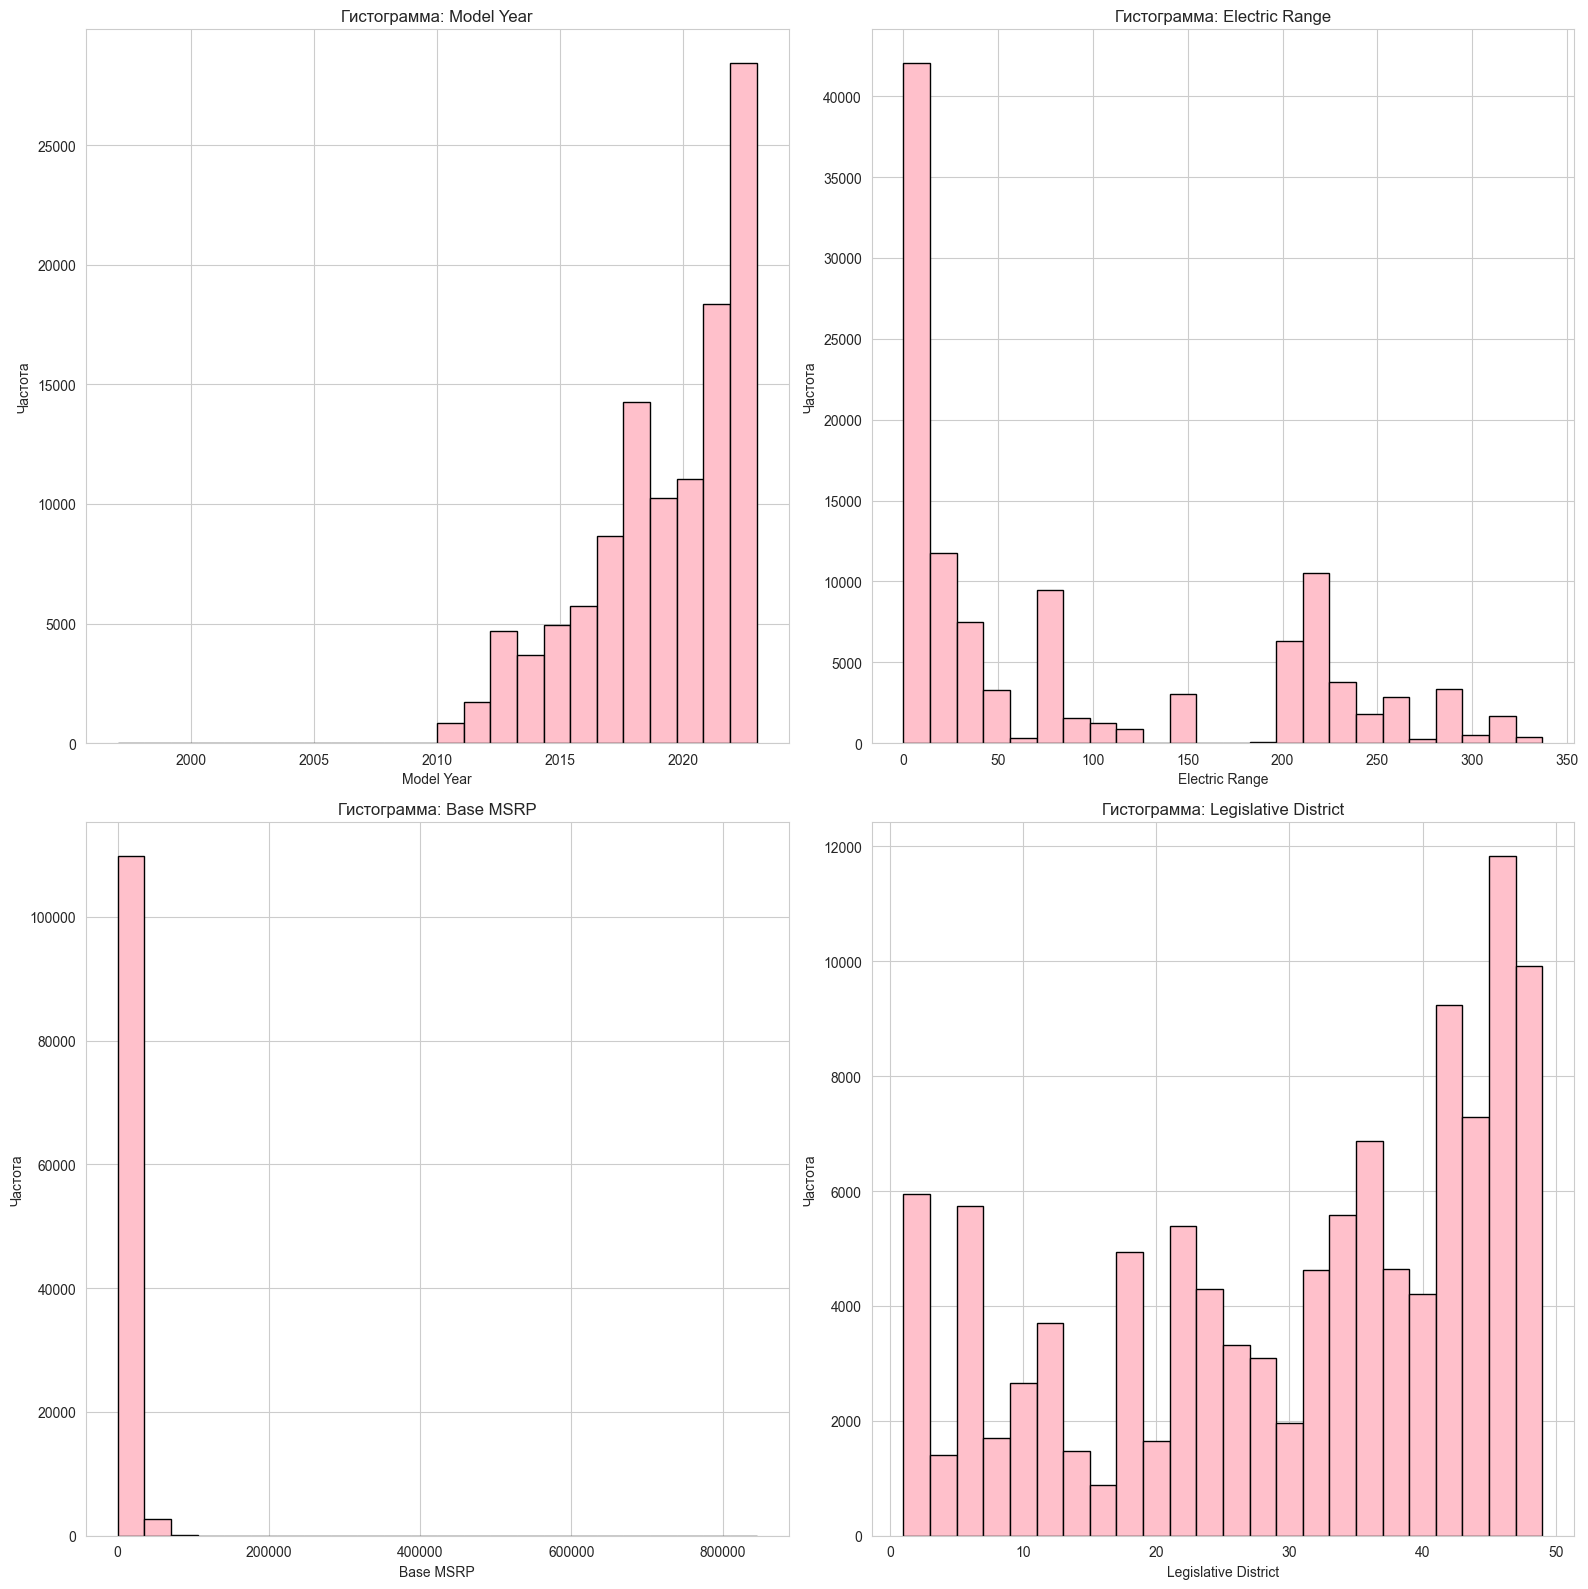

In [ ]:
numeric_cols = ['Model Year', 'Electric Range', 'Base MSRP', 'Legislative District']

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
axes = axes.flatten() # flatten - превращает двумерный массив в одномерный

for i, col in enumerate(numeric_cols):
    axes[i].hist(data[col].dropna(), bins=24, edgecolor='black', color='pink')
    axes[i].set_title(f'Гистограмма: {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Частота')

plt.tight_layout()
plt.show()

Ящик с усами по электрическому диапазону и типу автомобиля

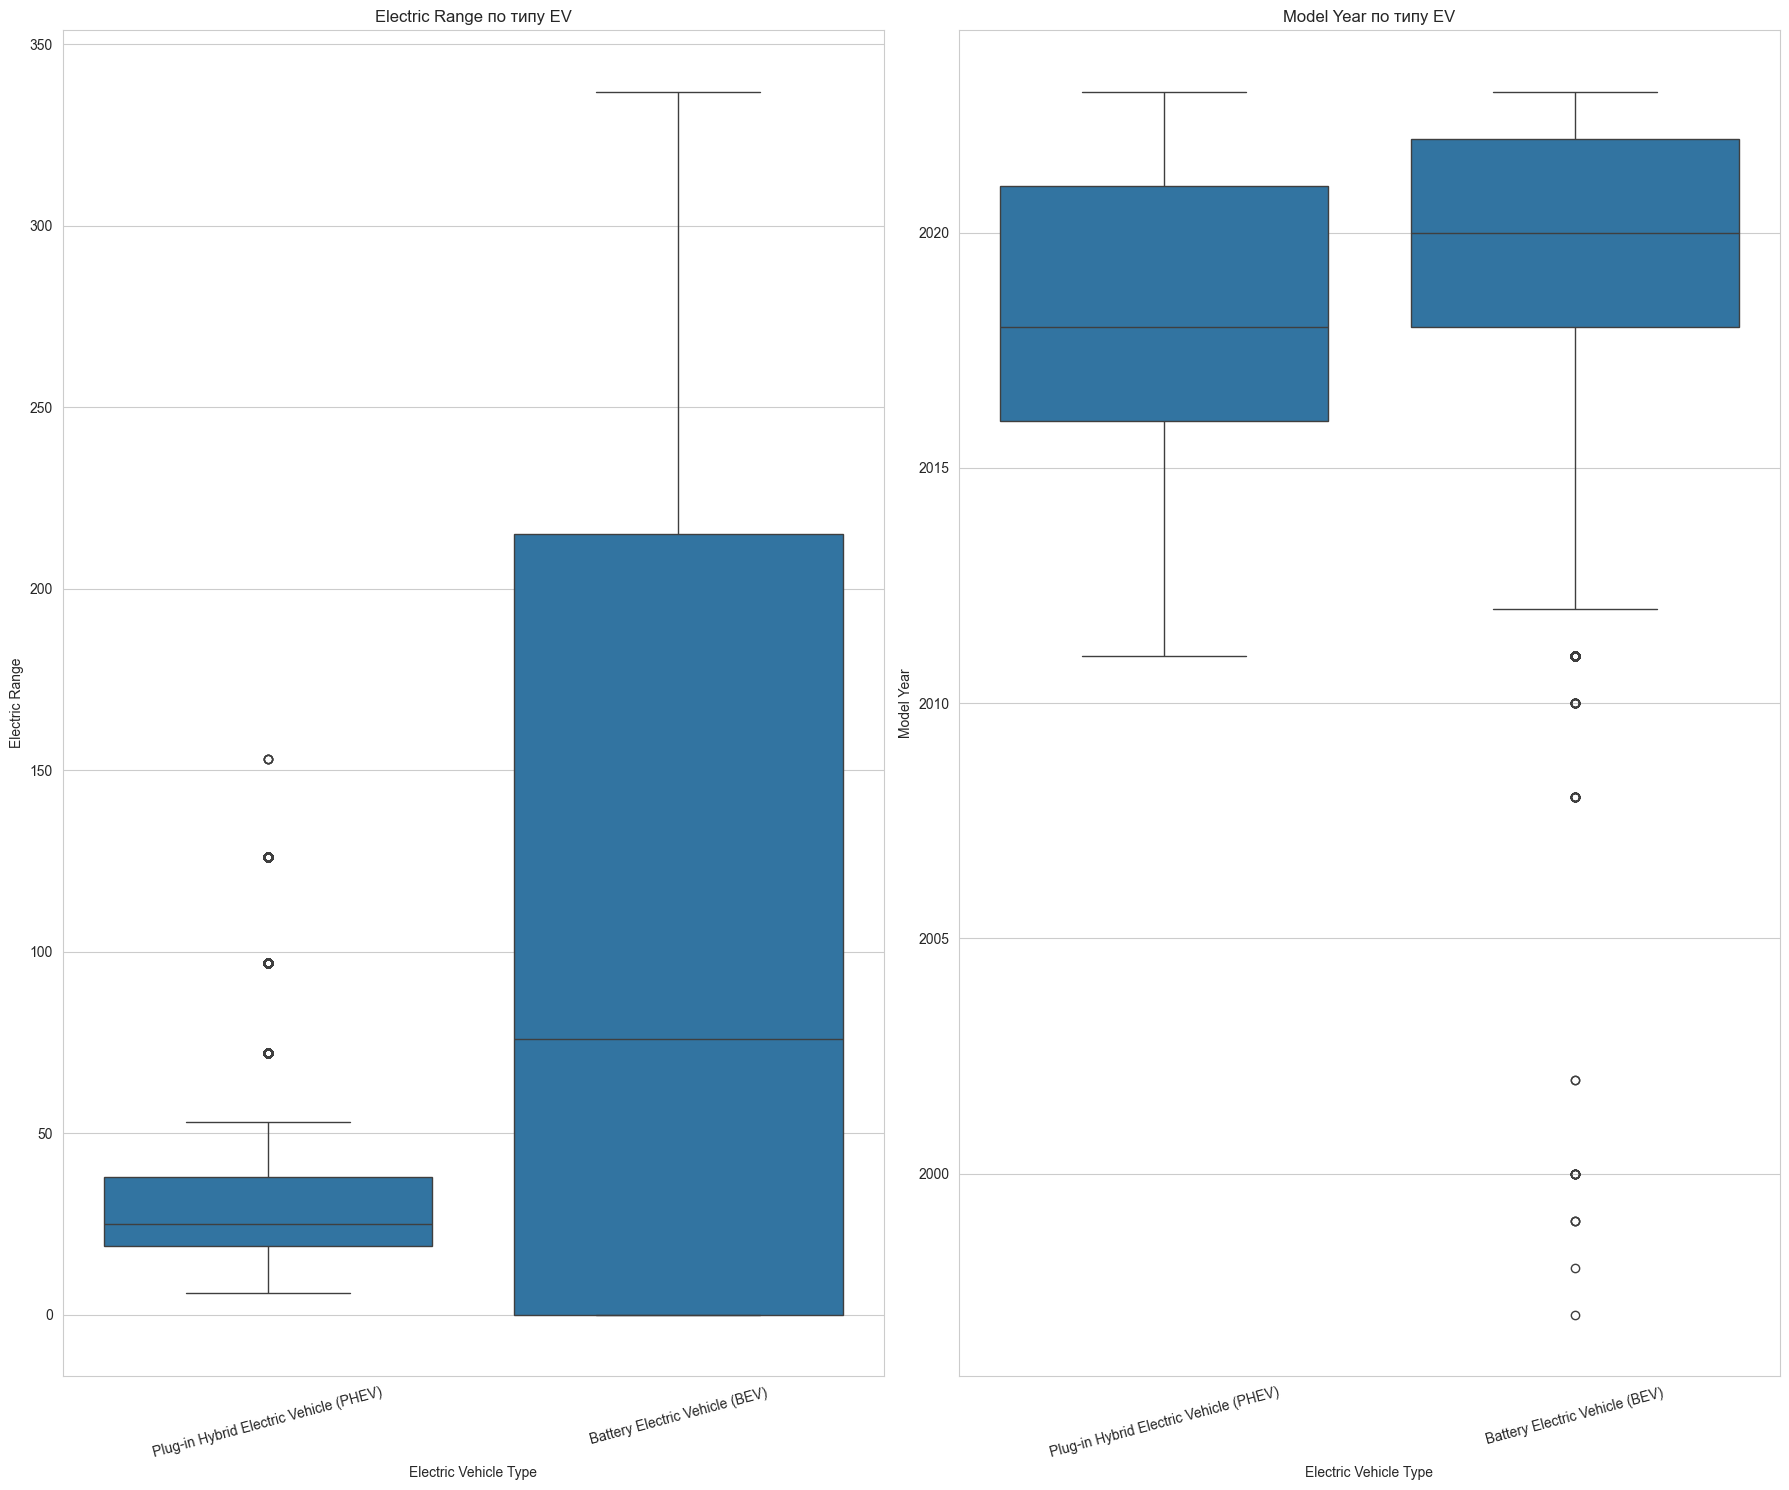

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(18, 15))

sns.boxplot(data=data, x='Electric Vehicle Type', y='Electric Range', ax=axes[0])
axes[0].set_title('Electric Range по типу EV')
axes[0].tick_params(axis='x', rotation=15)

sns.boxplot(data=data, x='Electric Vehicle Type', y='Model Year', ax=axes[1])
axes[1].set_title('Model Year по типу EV')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

Диаграмма рассеяния

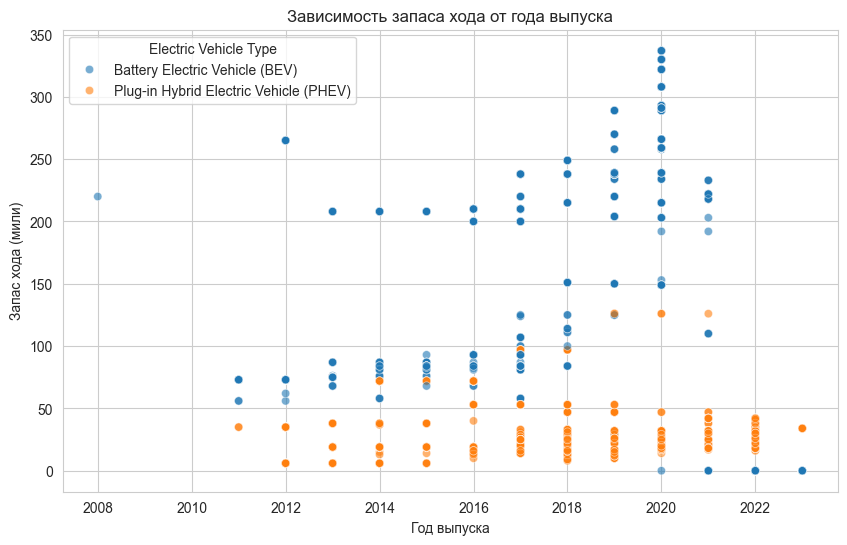

In [30]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=data.sample(5000, random_state=42),
    x='Model Year', y='Electric Range',
    hue='Electric Vehicle Type',
    alpha=0.6
)
plt.title('Зависимость запаса хода от года выпуска')
plt.xlabel('Год выпуска')
plt.ylabel('Запас хода (мили)')
plt.show()

Топ-10 марок и моделей

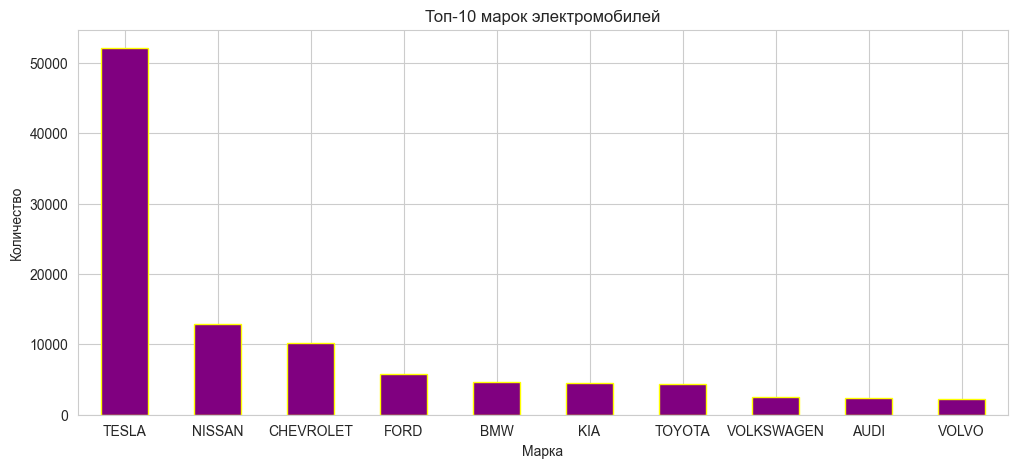

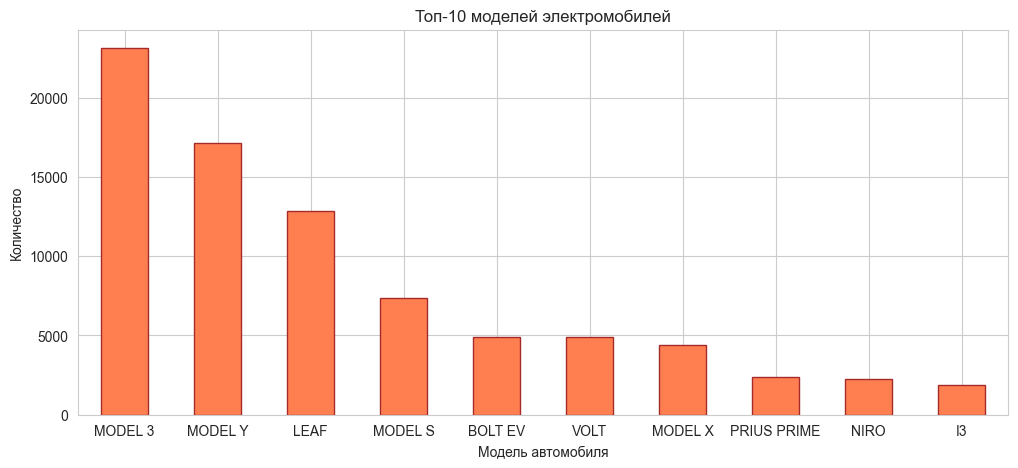

In [31]:
plt.figure(figsize=(12, 5))
data['Make'].value_counts().head(10).plot(kind='bar', color='purple', 
                                          edgecolor='yellow')
plt.title('Топ-10 марок электромобилей')
plt.xlabel('Марка')
plt.ylabel('Количество')
plt.xticks(rotation=360)

plt.figure(figsize=(12, 5))
data['Model'].value_counts().head(10).plot(kind='bar', color='coral',
                                            edgecolor='brown')
plt.title('Топ-10 моделей электромобилей')
plt.xlabel('Модель автомобиля')
plt.ylabel('Количество')
plt.xticks(rotation=360)
plt.show()

Очистка данных

Удаление лишних колонок

In [34]:
columns_to_drops = [
    'VIN (1-10)', #индефикатор - не несёт полезной информации
    'DOL Vehicle ID', #индефикатор тож самое
    'Vehicle Location', #Координаты машины - не зачем, бесполезная инфа
    '2020 Census Tract', #номер района - так же бесполезно
    'Base MSRP', #рекомендованная цена производителя - 99% нулей
    'State', #штат где почти всё WA - не несёт смысловой нагрузки
    'Model', #много уникальных
    'City', #много уникальных
    'Clean Alternative Fuel Vehicle (CAFV) Eligibility' #утечка данных
]
data_clean = data.drop(columns=columns_to_drops)

print("Было колонок: ", data.shape[1])
print("Стало колонок: ", data_clean.shape[1])
print('\n', data_clean.columns.tolist())

Было колонок:  17
Стало колонок:  8

 ['County', 'Postal Code', 'Model Year', 'Make', 'Electric Vehicle Type', 'Electric Range', 'Legislative District', 'Electric Utility']


Удаление пропусков

In [35]:
print("Пропуски до:")
print(data_clean.isnull().sum().sum(), "\n")
print(data_clean.isnull().sum(), "\n")

data_clean = data_clean.dropna()

print("Пропуски после: ")
print(data_clean.isnull().sum().sum())
print(data_clean.isnull().sum())
print("Строк осталось:", len(data_clean))

Пропуски до:
729 

County                     0
Postal Code                0
Model Year                 0
Make                       0
Electric Vehicle Type      0
Electric Range             0
Legislative District     286
Electric Utility         443
dtype: int64 

Пропуски после: 
0
County                   0
Postal Code              0
Model Year               0
Make                     0
Electric Vehicle Type    0
Electric Range           0
Legislative District     0
Electric Utility         0
dtype: int64
Строк осталось: 112191


Удаление дубликатов

In [36]:
print("Строк до: ", len(data_clean))

data_clean = data_clean.drop_duplicates()

print("Строк после: ", len(data_clean))
print("Удалено дубликатов: ", len(data) - len(data_clean))

Строк до:  112191
Строк после:  36433
Удалено дубликатов:  76201


Матрица корреляций

                      Postal Code  Model Year  Electric Range  \
Postal Code              1.000000   -0.016509        0.010640   
Model Year              -0.016509    1.000000       -0.145412   
Electric Range           0.010640   -0.145412        1.000000   
Legislative District    -0.496710    0.003029       -0.014991   

                      Legislative District  
Postal Code                      -0.496710  
Model Year                        0.003029  
Electric Range                   -0.014991  
Legislative District              1.000000  


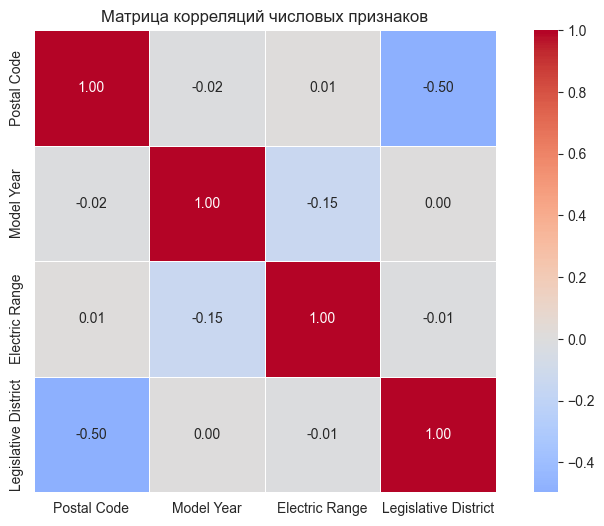

In [38]:
numeric_cols = data_clean.select_dtypes(include=['int64', 'float64']).columns
corr_matrix = data_clean[numeric_cols].corr()

print(corr_matrix)

plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title('Матрица корреляций числовых признаков')
plt.show()